# Georgia Gobernador 2026 · Modelo final (v11)
**Bottoms (D) vs Jackson (R)** · elección: 3-nov-2026 · se gana con más del 50% (si nadie lo supera, hay segunda vuelta)

La V11 combina lo mejor de todas las versiones (V5 a V10). Cada componente de las versiones anteriores pasó por el mismo backtest *leave-one-year-out*: 980 contiendas entre 1998 y 2024, 24 en Georgia (ver `../BACKTEST_GEORGIA`). Solo quedaron los que mejoran el pronóstico fuera de muestra; la sección 7 muestra el resultado de cada uno.

| Componente | Regla | Evidencia |
|---|---|---|
| Promedio de encuestas | recencia (vida media de 14 días) × √n, cada encuestadora pesa como una sola | backtest |
| Efectos de casa | sesgo relativo de cada encuestadora (histórico 1998–2024, contraído) | backtest nacional |
| Sesgo de Georgia | error histórico del estado, solo con ciclos pasados, vida media de 4 años, contracción bayes empírica | CRPS 3.455, el mejor |
| Incertidumbre | σ = √(τ² + s²/k), calibrada con los errores reales al mismo horizonte | cobertura de 81% y 95% (V9: 54% y 72%) |
| Colas Student-t (de V8-M3) | ν estimado con 701 errores históricos (≈10.5) | mejor CRPS y log-score: P(mejor) 0.86 nacional, 0.84 GA |
| Tres categorías (de V6–V8) | Bottoms / Jackson / Otros en encuestas, como reporte | las preguntas de dos opciones no cuentan para el residual |
| Indecisos | 50/50 | repartos sesgados empeoran el CRPS |
| Otros | solo write-ins: no hay terceros en la boleta (SOS, 15-sep) | write-ins históricos ≈ 0.002% |
| Kalshi | mezcla en logit con peso 0.30 | **no validado**: es un supuesto |
| Sentimiento | **no se usa** | sin serie histórica para validarlo; en California no aportó |
| Voto anticipado (M4-E de V5, con Civic Forge) | **solo diagnóstico** | con datos de 2018 a 2024 al mismo día, empeora el RMSE en GA |
| Senado (Ossoff–Collins) | mismo método; simulación conjunta con ρ = 0.42 | ρ de errores Gob–Sen del mismo estado y año: 120 pares, IC95 0.23–0.58 |
| Descartados | pesos 1/var, Kalman (V8-M2), shocks Poisson (V9), Beta de indecisos (V9), territorial M4-H | no mejoran o empeoran el CRPS |
| Prior estructural (lean + entorno nacional) | **solo como evidencia** | en gobernadores empeora el CRPS: 3.655 → 3.705 con β estimado y 3.971 con β = 0.20 |
| Edad, volumen del anticipado, gasto de campaña | **diagnóstico o fuera** | solo 2 comparaciones por tipo de ciclo; para el gasto no hay datos |

## 1. Configuración
Cambia `corte` cada vez que actualices. Las encuestas nuevas se agregan como filas en `datos/ga_gob2026_encuestas.csv` (columnas: pollster, clave_538, inicio, fin, n, pop, D, R, tipo_pregunta, fuente). **Antes de calcular, el modelo valida el archivo**: se detiene si hay duplicados, fechas inválidas, D+R > 100 o un tipo de pregunta desconocido, y avisa si una pregunta tipo general suma ~100 (probable reasignación de indecisos). Con `kalshi_en_vivo=True` se consulta la API pública; si falla, se usa la caché fechada y se indica en los resultados.

In [1]:
from datetime import date
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display
import georgia_modelo_final as gm
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

cfg = gm.Config(
    corte=date(2026, 10, 20),
    eleccion=date(2026, 11, 3),
    peso_kalshi=0.30,        # 0.0 = solo encuestas
    colas_t=True,            # False = distribución normal (V10)
    kalshi_en_vivo=False,    # True = consulta la API de Kalshi
    n_sim=100_000,
)
print('Días a la elección:', cfg.dias_a_eleccion)

Días a la elección: 14


## 2. Ejecutar

In [2]:
r = gm.ejecutar(cfg)
m = r['meta']
fin = r['resumen'].iloc[0]
print(f"Margen Bottoms − Jackson: {fin.margen_media:+.1f} pp  (σ = {fin.sd:.1f}, colas t con ν = {m['nu']})")
print(f"IC80: [{fin.IC80[0]:+.1f}, {fin.IC80[1]:+.1f}]   IC95: [{fin.IC95[0]:+.1f}, {fin.IC95[1]:+.1f}]")
print(f"Votos: Bottoms {fin.Bottoms_media:.1f}% · Jackson {fin.Jackson_media:.1f}% · write-ins ≈ 0.01%")
print(f"P(gana Bottoms) = {fin.P_Bottoms:.3f}   P(gana Jackson) = {fin.P_Jackson:.3f}   P(segunda vuelta) = {fin.P_segunda_vuelta:.4f}")
print()
print('Avisos de validación del CSV:', m['avisos_validacion_encuestas'] or 'ninguno')
print(f"Encuestas en ventana: {m['encuestas_en_ventana']} ({m['k_encuestadoras']} encuestadoras) desde {m['ventana']['ventana_desde']}"
      + ('  ⚠ VENTANA AMPLIADA' if m['ventana']['ampliada'] else ''))
print(f"Kalshi: P(D) = {m['kalshi']['p_D']:.3f} · fecha {m['kalshi']['fecha']} · {m['kalshi']['fuente']} · peso aplicado {m['peso_kalshi_aplicado']}")
if m['calibracion']['horizonte_recortado']:
    print('⚠ Corte a más de 21 días: σ calibrada a 21 días (subestima la incertidumbre a mayor horizonte)')

Margen Bottoms − Jackson: -1.4 pp  (σ = 5.4, colas t con ν = 11.8)
IC80: [-8.1, +5.3]   IC95: [-12.2, +9.4]
Votos: Bottoms 49.3% · Jackson 50.7% · write-ins ≈ 0.01%
P(gana Bottoms) = 0.389   P(gana Jackson) = 0.611   P(segunda vuelta) = 0.0017

Avisos de validación del CSV: ninguno
Encuestas en ventana: 3 (3 encuestadoras) desde 2026-10-13
Kalshi: P(D) = 0.490 · fecha 2026-10-20 · caché (consulta en vivo desactivada) · peso aplicado 0.3


## 3. Escenarios y sensibilidad
Cada fila cambia una sola pieza respecto al modelo final.

In [3]:
T = r['resumen'].copy()
T['IC80'] = T.IC80.map(lambda x: f'[{x[0]:+.1f}, {x[1]:+.1f}]')
T['IC95'] = T.IC95.map(lambda x: f'[{x[0]:+.1f}, {x[1]:+.1f}]')
display(T[['escenario','margen_media','sd','IC80','IC95','Bottoms_media','Jackson_media','P_Bottoms','P_segunda_vuelta']].round(3))

,escenario,margen_media,sd,IC80,IC95,Bottoms_media,Jackson_media,P_Bottoms,P_segunda_vuelta
0,FINAL: encuestas + Kalshi,-1.404,5.419,"[-8.1, +5.3]","[-12.2, +9.4]",49.293,50.697,0.389,0.002
1,Solo encuestas (sin Kalshi),-1.956,5.419,"[-8.6, +4.8]","[-12.8, +8.8]",49.017,50.973,0.348,0.002
2,Distribución normal (= v10),-1.420,5.416,"[-8.4, +5.5]","[-12.0, +9.2]",49.285,50.705,0.396,0.001
3,Sin sesgo estatal GA,-1.287,5.419,"[-7.9, +5.4]","[-12.1, +9.5]",49.351,50.638,0.398,0.002
4,Sin efectos de casa,-2.154,5.419,"[-8.8, +4.6]","[-13.0, +8.6]",48.918,51.072,0.334,0.001
5,Ventana 30 días,-2.202,4.469,"[-7.7, +3.3]","[-11.1, +6.7]",48.894,51.096,0.299,0.002
6,Ventana 45 días,-2.305,4.198,"[-7.5, +2.9]","[-10.7, +6.0]",48.842,51.147,0.278,0.002
7,Kalshi solo,-0.110,5.419,"[-6.8, +6.6]","[-10.9, +10.7]",49.940,50.050,0.491,0.002


## 4. Encuestas: margen observado y corregido
`efecto_casa` < 0 indica una encuestadora históricamente inclinada a R; al corregir, su margen se mueve hacia D. Las encuestadoras sin historial (Quantus, Big Data Poll, Wedgewood, State Navigate, G-Ratings) entran sin corrección.

In [4]:
E = r['encuestas']
E['en_ventana'] = E.index.isin(r['ventana'].index)
display(E[['fin','pollster','pop','n','D','R','margin_poll','efecto_casa','margen_corregido','tipo_pregunta','en_ventana']].sort_values('fin', ascending=False).round({'efecto_casa': 2, 'margen_corregido': 2, 'margin_poll': 2}))

,fin,pollster,pop,n,D,R,margin_poll,efecto_casa,margen_corregido,tipo_pregunta,en_ventana
14,2026-10-17,Quantus Insights,LV,755,46.6,48.2,-1.6,0.00,-1.60,general,True
13,2026-10-15,AJC / University of Georgia SPIA,LV,1000,45.0,46.0,-1.0,-0.06,-0.94,general,True
12,2026-10-13,InsiderAdvantage,LV,800,47.0,49.0,-2.0,-0.60,-1.40,general,True
11,2026-10-03,Wedgewood Polls,LV,600,49.0,51.0,-2.0,0.00,-2.00,dos_opciones,False
10,2026-09-29,G-Ratings,RV,1000,45.3,47.5,-2.2,0.00,-2.20,general,False
8,2026-09-23,Big Data Poll,LV,678,46.7,48.8,-2.1,0.00,-2.10,general,False
9,2026-09-23,InsiderAdvantage,LV,1200,46.0,48.0,-2.0,-0.60,-1.40,general,False
7,2026-09-18,YouGov,LV,3000,44.0,46.0,-2.0,0.35,-2.35,general,False
6,2026-09-14,Rasmussen Reports,LV,1019,45.0,48.0,-3.0,-1.08,-1.92,general,False
5,2026-08-17,InsiderAdvantage,LV,800,46.2,46.3,-0.1,-0.60,0.50,general,False


## 5. Gráficas

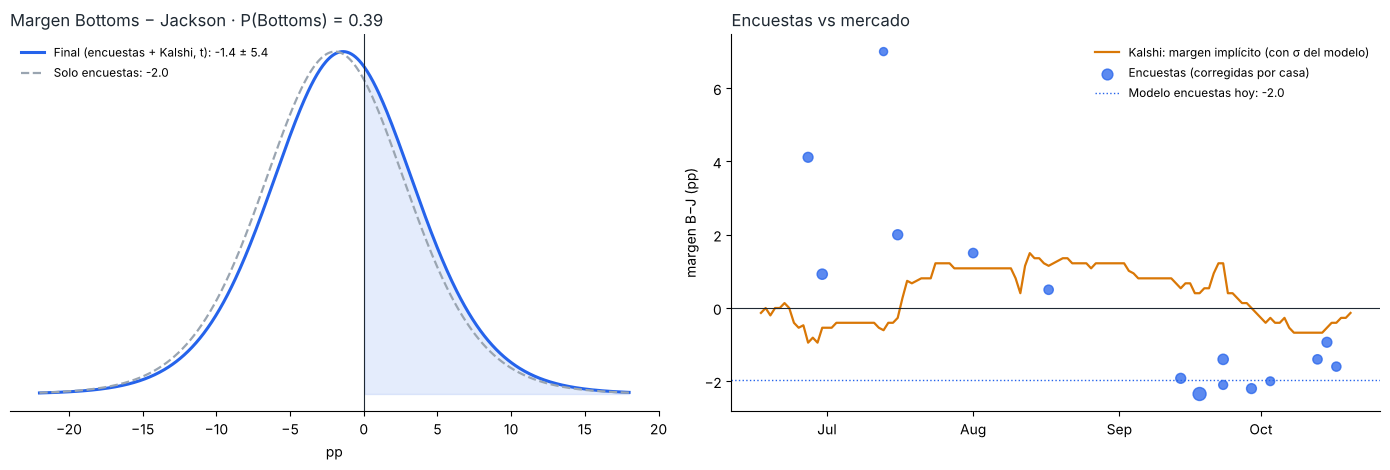

In [5]:
ink, acc, mute, warm = '#1f2933', '#2563eb', '#9aa5b1', '#d97706'
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) distribución del margen
x = np.linspace(-22, 18, 600)
a = ax[0]
from scipy.stats import t as st_t
sc = fin.sd * np.sqrt((m['nu'] - 2) / m['nu']) if m['nu'] else fin.sd
pdf_fin = st_t.pdf((x - fin.margen_media) / sc, m['nu']) / sc if m['nu'] else norm.pdf(x, fin.margen_media, fin.sd)
a.plot(x, pdf_fin, color=acc, lw=2.2, label=f'Final (encuestas + Kalshi, t): {fin.margen_media:+.1f} ± {fin.sd:.1f}')
e = T.set_index('escenario').loc['Solo encuestas (sin Kalshi)']
a.plot(x, st_t.pdf((x - e.margen_media) / sc, m['nu']) / sc if m['nu'] else norm.pdf(x, e.margen_media, e.sd), color=mute, lw=1.6, ls='--', label=f'Solo encuestas: {e.margen_media:+.1f}')
a.fill_between(x[x > 0], pdf_fin[x > 0], color=acc, alpha=.12)
a.axvline(0, color=ink, lw=.8)
a.set_title(f'Margen Bottoms − Jackson · P(Bottoms) = {fin.P_Bottoms:.2f}', loc='left', color=ink)
a.set_xlabel('pp'); a.set_yticks([]); a.legend(frameon=False, fontsize=8.5, loc='upper left')
a.spines[['top','right','left']].set_visible(False)

# (b) encuestas corregidas y margen implícito de Kalshi en el tiempo
b = ax[1]
k = pd.read_csv(gm.DATA / 'kalshi_GOVPARTYGA-26-D_diario.csv', parse_dates=['date_utc'])
k = k[k.date_utc <= pd.Timestamp(cfg.corte) + pd.Timedelta(days=1)]
mid = (k.yes_bid_close + k.yes_ask_close) / 2
pk = mid / (mid + (1 - mid + cfg.sobreprecio_kalshi))
b.plot(k.date_utc, fin.sd * norm.ppf(pk), color=warm, lw=1.6, label='Kalshi: margen implícito (con σ del modelo)')
b.scatter(E.fin, E.margen_corregido, s=np.sqrt(E.n) * 1.6, color=acc, alpha=.75, label='Encuestas (corregidas por casa)', zorder=3)
b.axhline(0, color=ink, lw=.8); b.axhline(m['mu_encuestas'], color=acc, lw=1, ls=':', label=f"Modelo encuestas hoy: {m['mu_encuestas']:+.1f}")
import matplotlib.dates as mdates
b.xaxis.set_major_locator(mdates.MonthLocator()); b.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
b.set_title('Encuestas vs mercado', loc='left', color=ink); b.set_ylabel('margen B−J (pp)')
b.legend(frameon=False, fontsize=8.5, loc='upper right'); b.spines[['top','right']].set_visible(False)
fig.tight_layout(); fig.savefig(cfg.salida / 'pronostico_georgia_v11.png', dpi=150); plt.show()

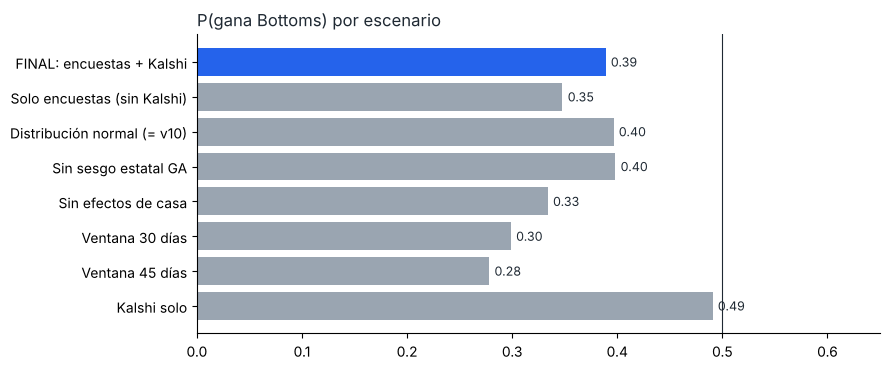

In [6]:
fig, a = plt.subplots(figsize=(9, 3.8))
t = r['resumen'].iloc[::-1]
cols = [acc if s.startswith('FINAL') else mute for s in t.escenario]
a.barh(t.escenario, t.P_Bottoms, color=cols)
a.axvline(.5, color=ink, lw=.8)
for y, v in enumerate(t.P_Bottoms): a.text(v + .005, y, f'{v:.2f}', va='center', fontsize=9, color=ink)
a.set_xlim(0, .65); a.set_title('P(gana Bottoms) por escenario', loc='left', color=ink)
a.spines[['top','right']].set_visible(False); fig.tight_layout(); plt.show()

In [7]:
ev = gm.DATA / 'evidencia_backtest'

## 5b. Tres categorías en encuestas (de V6–V8)
Son porcentajes de **respuesta** en las encuestas de la ventana, no de voto. Las preguntas de dos opciones o con indecisos reasignados se excluyen del residual. En el pronóstico, el residual se reparte 50/50 (es la regla validada) y no hay terceros en la boleta.

In [8]:
tc = r['tres_categorias']
display(pd.DataFrame([tc]).drop(columns='nota').round(2))

,n_encuestas,Bottoms_encuesta,Jackson_encuesta,Otros_ninguno_indecisos
0,3,46.14,47.64,6.22


## 5c. Diagnóstico del voto anticipado (M4-E de V5, con datos de Civic Forge)
Composición de las boletas aceptadas **al mismo número de días antes de la elección** (15), de 2018 a 2026. Fuente: API pública de Civic Forge (CC BY 4.0), basada en los archivos de voto ausente del SOS.

**No entra al pronóstico.** En el backtest de Georgia 2018–2024, corregir el error de las encuestas con la participación negra empeoró el RMSE (2.94 contra 1.63 sin corregir) y la pendiente cambia de signo según el ciclo que se deja fuera. Se muestra para vigilar la recta final.

,anio,fecha_matched,dias_eleccion,total,negro_pct,blanco_pct
0,2018,2018-10-22,15,636152,30.06,60.37
1,2020,2020-10-19,15,1757649,30.50,56.33
2,2022,2022-10-24,15,998391,32.19,55.83
3,2024,2024-10-21,15,1703778,27.43,59.04
4,2026,2026-10-19,15,1027033,34.79,52.01


% negro de las boletas a 15 días: 2026 vs 2022 = +2.6 pp  (fuente: caché)


,race,year,negro_pct,error_real,pred_error_con_raza,pred_error_media,pendiente_LOYO
0,2018_Gov-G_GA,2018,30.06,0.64,0.75,0.65,-0.19
1,2020_Pres-G_GA,2020,30.50,1.23,-0.05,-0.04,-0.19
2,2020_Sen-G_GA,2020,30.50,2.86,-0.05,-0.04,-0.19
3,2022_Gov-G_GA,2022,32.19,1.06,2.53,1.25,0.50
4,2022_Sen-G_GA,2022,32.19,-2.15,2.53,1.25,0.50
5,2024_Pres-G_GA,2024,27.43,0.27,4.47,0.73,-1.02


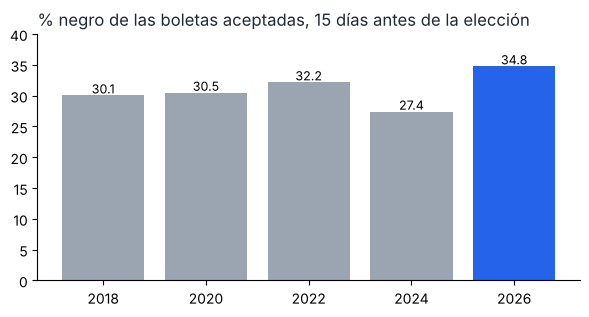

In [9]:
v = gm.voto_anticipado_diagnostico(cfg)
display(v['tabla'].round(2))
print(f"% negro de las boletas a 15 días: 2026 vs 2022 = {v['delta_negro_vs_2022']:+.1f} pp  (fuente: {v['fuente']})")
ev_ = pd.read_csv(gm.DATA / 'evidencia_backtest' / 'E_voto_anticipado_raza_LOYO.csv')
display(ev_.round(2))
fig, a = plt.subplots(figsize=(7, 3.2))
tb = v['tabla']; a.bar(tb.anio.astype(str), tb.negro_pct, color=[acc if y == 2026 else mute for y in tb.anio])
for i_, val in enumerate(tb.negro_pct): a.text(i_, val + .3, f'{val:.1f}', ha='center', fontsize=9)
a.set_title('% negro de las boletas aceptadas, 15 días antes de la elección', loc='left', color=ink); a.set_ylim(0, 40)
a.spines[['top','right']].set_visible(False); plt.show()

## 5d. Senado (Ossoff vs Collins) y probabilidad conjunta
El Senado se modela con el mismo método. Las dos carreras se simulan juntas con una t bivariada: los errores de encuestas de Gobernador y Senado en el mismo estado y año tienen ρ = 0.42 (120 pares, 1998–2024). La probabilidad de Bottoms por sí sola no cambia; cambian la conjunta y las condicionales (por ejemplo, la del voto dividido).

In [10]:
sen, cj = m['senado'], m['conjunto_gob_sen']
print(f"Senado: Ossoff − Collins = {sen['mu']:+.1f} pp (σ = {sen['sd']:.1f}, k = {sen['k']}) · P(Ossoff) = {sen['P_Ossoff']:.3f} · IC80 [{sen['IC80'][0]:+.1f}, {sen['IC80'][1]:+.1f}]"
      + ('  ⚠ ventana ampliada desde ' + sen['ventana']['ventana_desde'] if sen['ventana']['ampliada'] else ''))
tabla_cj = pd.DataFrame([[cj['P_Bottoms_y_Ossoff'], cj['P_Bottoms_y_Collins']], [cj['P_Jackson_y_Ossoff'], cj['P_Jackson_y_Collins']]],
                        index=['Bottoms gana', 'Jackson gana'], columns=['Ossoff gana', 'Collins gana'])
display(tabla_cj.round(3))
print(f"P(Bottoms | gana Ossoff) = {cj['P_Bottoms_si_gana_Ossoff']:.3f}   P(Bottoms | gana Collins) = {cj['P_Bottoms_si_gana_Collins']:.3f}")
print(f"P(voto dividido entre carreras) = {cj['P_division_de_voto']:.3f}   ρ usada = {cj['rho']} (simulada {cj['corr_simulada']:.3f})")
display(r['senado']['encuestas_senado'][['fin','pollster','pop','n','D','R','margin_poll','efecto_casa','margen_corregido']].sort_values('fin', ascending=False).round({'margin_poll':2,'efecto_casa':2,'margen_corregido':2}))

Senado: Ossoff − Collins = +8.2 pp (σ = 6.2, k = 2) · P(Ossoff) = 0.913 · IC80 [+0.5, +15.9]  ⚠ ventana ampliada desde 2026-10-09


,Ossoff gana,Collins gana
Bottoms gana,0.376,0.013
Jackson gana,0.536,0.075


P(Bottoms | gana Ossoff) = 0.412   P(Bottoms | gana Collins) = 0.143
P(voto dividido entre carreras) = 0.549   ρ usada = 0.42 (simulada 0.420)


,fin,pollster,pop,n,D,R,margin_poll,efecto_casa,margen_corregido
13,2026-10-17,Quantus Insights,LV,755,51.8,44.9,6.9,0.00,6.90
12,2026-10-09,Trafalgar Group,LV,1101,51.0,43.0,8.0,-3.26,11.26
11,2026-10-03,Wedgewood Polls,LV,600,55.0,45.0,10.0,0.00,10.00
10,2026-09-29,G-Ratings,RV,1000,50.5,41.4,9.1,0.00,9.10
8,2026-09-23,Big Data Poll,LV,678,52.2,41.0,11.2,0.00,11.20
9,2026-09-23,InsiderAdvantage,LV,1200,50.0,42.0,8.0,-0.60,8.60
7,2026-09-18,YouGov,LV,3000,52.0,42.0,10.0,0.35,9.65
6,2026-09-16,Quantus Insights,LV,645,48.2,44.4,3.8,0.00,3.80
5,2026-09-14,Rasmussen Reports,LV,1019,51.0,42.0,9.0,-1.08,10.08
4,2026-09-12,Trafalgar Group,LV,1091,49.4,42.8,6.6,-3.26,9.86


## 5e. Observaciones externas validadas (20-oct)
Se probaron en el mismo backtest. El prior estructural mejora en Georgia (21 contiendas), pero **empeora en las 232 contiendas a gobernador del país**, que son el análogo relevante, sobre todo con el peso de 0.20 que se sugirió. Por eso no entra. La composición por edad del voto anticipado se muestra como diagnóstico.

In [11]:
display(pd.read_csv(ev / 'G_prior_estructural.csv').round(3))
display(pd.read_csv(ev / 'H_correlacion_gob_sen.csv').round(3))
ed = pd.read_csv(gm.DATA / 'civicforge_edad_T15.csv')
tot = ed[['e18_34','e35_54','e55_64','e65','NA','UNKNOWN']].sum(axis=1)
display(ed.assign(pct_18_34=100*ed.e18_34/tot, pct_65mas=100*ed.e65/tot, boletas=tot)[['anio','tipo_ciclo','boletas','pct_18_34','pct_65mas']].round(1))

,ambito,modo,n,beta_medio,RMSE,CRPS,LogScore,Cob80,horizonte
0,Nacional,sin_prior,701,0.000,6.372,3.453,3.224,0.793,15
1,Nacional_Gob,sin_prior,232,0.000,6.679,3.655,3.280,0.767,15
2,GA_generales,sin_prior,21,0.000,5.608,2.755,2.915,0.857,15
3,Nacional,beta_LOYO,701,0.080,6.306,3.423,3.219,0.780,15
4,Nacional_Gob,beta_LOYO,232,0.082,6.764,3.705,3.301,0.750,15
5,GA_generales,beta_LOYO,21,0.081,5.131,2.573,2.869,0.857,15
6,Nacional,fijo_0.20,701,0.200,6.448,3.500,3.245,0.787,15
7,Nacional_Gob,fijo_0.20,232,0.200,7.245,3.971,3.380,0.733,15
8,GA_generales,fijo_0.20,21,0.200,4.802,2.468,2.862,0.857,15
9,Nacional,sin_prior,980,0.000,5.573,3.044,3.095,0.788,0


,n_pares_estado_anio,rho_errores,rho_IC95,rho_sin_componente_anual
0,120,0.416,"(0.22650189100528564, 0.5810487786614372)",0.283


,anio,tipo_ciclo,boletas,pct_18_34,pct_65mas
0,2018,intermedia,636152,9.9,42.1
1,2020,presidencial,1757649,13.9,37.3
2,2022,intermedia,998391,8.7,44.8
3,2024,presidencial,1703778,13.3,39.2
4,2026,intermedia,1027033,10.1,46.8


## 6. Evidencia del backtest (por qué este modelo)
Validación *leave-one-year-out* a 15 días de la elección. **CRPS: menor es mejor.** Cob80 y Cob95 deberían quedar cerca de 0.80 y 0.95.

In [12]:
R = pd.read_csv(ev / 'metricas_h15.csv'); Cd = pd.read_csv(ev / 'C_sesgo_estado_decaimiento.csv')
nombres = {'pond|sd_V9(2pp)': 'V9: encuestas + σ con piso de 2 pp', 'pond|sd_empirica': 'Encuestas + σ empírica',
           'casa|sd_empirica': '+ efectos de casa', 'casa_part|fundamentales+sd_emp': '+ fundamentales',
           'pond|sesgo_hist+sd_emp': '+ sesgo histórico promedio'}
filas = []
for mod, lab in nombres.items():
    for amb, nom in [('Nacional_todas', 'Nacional'), ('GA_generales', 'GA_generales')]:
        x = R[(R.ambito == amb) & (R.modelo == mod)].iloc[0]
        filas.append({'modelo': lab, 'ámbito': nom, 'n': x.n, 'RMSE': x.RMSE, 'CRPS': x.CRPS, 'Cob80': x.Cob80, 'Cob95': x.Cob95})
for nom in ['Nacional', 'GA_generales']:
    x = Cd[(Cd.ambito == nom) & (Cd.vida_media_anios == 4)].iloc[0]
    filas.append({'modelo': '★ FINAL: casa + sesgo GA (4 años)', 'ámbito': nom, 'n': x.n, 'RMSE': x.RMSE, 'CRPS': x.CRPS, 'Cob80': x.Cob80, 'Cob95': x.Cob95})
display(pd.DataFrame(filas).pivot(index='modelo', columns='ámbito', values=['CRPS', 'Cob80', 'Cob95']).round(3).sort_values(('CRPS', 'Nacional')))
print('Indecisos dentro del modelo final:')
display(pd.read_csv(ev / 'D_indecisos_en_modelo_ganador.csv')[['ambito','regla_indecisos','CRPS','RMSE','sesgo']].round(3))
print('Bootstrap por año (diferencia de CRPS, negativo = gana el modelo final):')
display(pd.read_csv(ev / 'B_bootstrap_crps.csv').round(3))

CRPS                 Cob80                 Cob95         
ámbito                             GA_generales Nacional GA_generales Nacional GA_generales Nacional
modelo                                                                                              
★ FINAL: casa + sesgo GA (4 años)         2.783    3.455        0.905    0.810        0.952    0.946
+ fundamentales                           2.728    3.479        0.905    0.792        1.000    0.944
+ efectos de casa                         2.914    3.516        0.857    0.802        1.000    0.947
Encuestas + σ empírica                    2.812    3.525        0.857    0.805        1.000    0.943
+ sesgo histórico promedio                3.213    3.624        0.857    0.812        0.905    0.934
V9: encuestas + σ con piso de 2 pp        2.848    3.725        0.667    0.544        0.810    0.718

Indecisos dentro del modelo final:


,ambito,regla_indecisos,CRPS,RMSE,sesgo
0,Nacional,50/50,3.455,6.372,0.950
1,GA_generales,50/50,2.783,5.608,1.559
2,GA_2014+,50/50,1.547,2.412,-0.442
3,Nacional,s_LOYO,3.489,6.431,0.396
4,GA_generales,s_LOYO,2.844,5.760,1.003
5,GA_2014+,s_LOYO,1.551,2.413,-0.475
6,Nacional,s=0.436 (V9),3.545,6.526,1.700
7,GA_generales,s=0.436 (V9),2.837,5.692,2.209
8,GA_2014+,s=0.436 (V9),1.574,2.417,-0.385


Bootstrap por año (diferencia de CRPS, negativo = gana el modelo final):


,A,B,n,dif_media(A-B),IC95_bajo,IC95_alto,P(A mejor),ambito
0,casa_part|sesgo_estado+sd_emp,pond|sd_empirica,701,-0.067,-0.169,0.036,0.899,Nacional
1,casa_part|sesgo_estado+sd_emp,pond|sd_V9(2pp),701,-0.267,-0.455,-0.092,0.999,Nacional
2,casa_part|sesgo_estado+sd_emp,casa_part|fundamentales+sd_emp,701,-0.020,-0.159,0.127,0.600,Nacional
3,casa_part|sesgo_estado+sd_emp,casa_part|sd_empirica,701,-0.056,-0.157,0.037,0.865,Nacional
4,casa_part|sesgo_estado+sd_emp,pond|sd_empirica,24,-0.069,-0.395,0.277,0.658,GA
5,casa_part|sesgo_estado+sd_emp,pond|sd_V9(2pp),24,-0.148,-0.766,0.386,0.676,GA
6,casa_part|sesgo_estado+sd_emp,casa_part|fundamentales+sd_emp,24,0.041,-0.217,0.320,0.384,GA
7,casa_part|sesgo_estado+sd_emp,casa_part|sd_empirica,24,-0.132,-0.517,0.247,0.752,GA


### Componentes de todas las versiones probados en el backtest
Mismo marco (a 15 días de la elección, dejando fuera cada año); se parte de V10 y se cambia una pieza a la vez. **CRPS: menor es mejor.**

In [13]:
Ev = pd.read_csv(ev / 'E_componentes_versiones.csv')
display(Ev.pivot(index='variante', columns='ambito', values='CRPS').round(3).sort_values('Nacional'))
print('Bootstrap por año, colas t contra la base (negativo = gana la t):')
display(pd.read_csv(ev / 'F_bootstrap_t_vs_base.csv').round(4))

ambito,GA_2014+,GA_generales,Nacional
variante,,,
T colas Student-t (V8-M3),1.514,2.763,3.450
"V10 base (√n, HL14, 1/rep)",1.547,2.783,3.455
S shocks Poisson V9 (+var),1.559,2.791,3.456
W2 HL 30 días,1.561,2.787,3.456
W3 firma 1/√rep (V9),1.546,2.785,3.456
W2 HL 5 días (V8),1.509,2.777,3.457
W1 pesos 1/var (V8/V9),1.565,2.778,3.464
K Kalman nivel local (V8-M2),1.554,2.785,3.475


Bootstrap por año, colas t contra la base (negativo = gana la t):


,ambito,modelo,dif_CRPS_vs_base,IC95_bajo,IC95_alto,P(mejor)
0,Nacional,t,-0.0051,-0.0135,0.0041,0.8608
1,Nacional,t + HL5,-0.0025,-0.0205,0.0142,0.6170
2,GA,t,-0.0208,-0.0529,0.0246,0.8395
3,GA,t + HL5,-0.0262,-0.0670,0.0131,0.8965


## 7. Errores históricos de las encuestas en Georgia (al mismo horizonte)
Positivo = las encuestas sobrestimaron al demócrata. De aquí sale el sesgo estatal, que pondera más los ciclos recientes.

In [14]:
G = pd.read_csv(cfg.salida / 'errores_historicos_GA.csv')
c = m['calibracion']
print(f"Sesgo GA bruto (ponderado) {c['sesgo_estado_bruto']:+.2f} × contracción {c['contraccion_sesgo']:.2f} = {c['sesgo_estado']:+.2f} pp")
print(f"τ = {c['tau']:.2f}, s = {c['s']:.2f} (σ con k encuestadoras = √(τ² + s²/k)); {c['n_contiendas']} contiendas de calibración")
display(G.sort_values('year', ascending=False).round(2))

Sesgo GA bruto (ponderado) +0.89 × contracción 0.75 = +0.67 pp
τ = 3.25, s = 7.50 (σ con k encuestadoras = √(τ² + s²/k)); 752 contiendas de calibración


,race,year,location,k,e
25,2024_Pres-G_GA,2024,GA,11,0.46
23,2022_Gov-G_GA,2022,GA,3,1.06
24,2022_Sen-G_GA,2022,GA,6,-2.29
19,2020_Pres-G_GA,2020,GA,8,1.23
22,2020_Sen-G_GA,2020,GA,7,2.86
21,2020_Sen-GSR_GA,2020,GA,6,-1.43
20,2020_Sen-GR_GA,2020,GA,6,-1.05
18,2018_Gov-G_GA,2018,GA,2,0.64
16,2016_Pres-G_GA,2016,GA,5,4.02
17,2016_Sen-G_GA,2016,GA,5,-0.05


## 8. Limitaciones y actualización
- **Kalshi (w = 0.30):** es un supuesto, el mismo peso que California M5. Solo hay un caso para compararlo (GA-2024, donde el modelo superó al mercado). Para validarlo hacen falta los mercados estatales de 2024 junto con los promedios de encuestas a 15 días.
- **Encuestadoras sin historial:** Quantus, Big Data Poll, Wedgewood, State Navigate y G-Ratings no tienen efecto de casa estimado.
- **Histórico:** FiveThirtyEight termina en 2022; GA-2024 se agregó a mano.
- **σ con k bajo:** con pocas encuestadoras en la ventana, σ es grande a propósito; así quedó calibrado.
- **Para actualizar:**
  1. Agrega las encuestas nuevas al CSV.
  2. Cambia `corte`.
  3. Opcional: `kalshi_en_vivo=True` (si la red no alcanza Kalshi, se usa la caché y se indica).
  4. Ejecuta todo. Cada corrida se agrega a `salida/historial_pronosticos.csv`.
- **Pruebas:** `py pruebas.py` (17 pruebas; escribe en una carpeta temporal y no toca `salida/`).
- Las encuestas del Senado van en `datos/ga_sen2026_encuestas.csv`, con el mismo formato (D = Ossoff, R = Collins).

In [15]:
print('Archivos en', cfg.salida)
for p in sorted(cfg.salida.glob('*.*')): print(' ·', p.name)

Archivos en salida
 · encuestas_corregidas.csv
 · encuestas_senado_corregidas.csv
 · errores_historicos_GA.csv
 · historial_pronosticos.csv
 · metadatos.json
 · pronostico_georgia_v11.png
 · resumen_escenarios.csv
 · senado_y_conjunto.csv
 · simulaciones_muestra.csv
 · tres_categorias_encuestas.csv
